# 03 · Representação e índices

Este notebook constrói e compara as duas representações da base de conhecimento: o índice lexical (BM25 sobre radicais, `src/indexing/lexical.py`) e o índice vetorial (embeddings de sentença em FAISS, `src/indexing/vetorial.py`). O TF-IDF entra só como comparação. Os dois índices têm uma entrada por texto distinto (34.889), na mesma ordem, o que permite combiná-los depois.

Os índices são gerados por `make index`; os embeddings levam cerca de 7 minutos em CPU e ficam em `data/index/embeddings.npz`, em float16.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import time
import warnings

warnings.filterwarnings("ignore")
os.environ["TQDM_DISABLE"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.indexing.lexical import LexicalIndex, TfidfIndex
from src.indexing.vetorial import MODEL_NAME, VectorIndex, embed, load_model
from src.visualization.estilo import BLUE, DELIVERY_COLORS, GRAY, GREEN, ORANGE, RED, apply_style, fmt_pct, save
from src.visualization.rotulos import DELIVERY_LABELS

apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

docs = pd.read_parquet("data/processed/documentos.parquet")
lexical = LexicalIndex.load()
tfidf = TfidfIndex.from_lexical(lexical)
vector = VectorIndex.load()
model = load_model()
rep = docs[docs["is_representative"]].set_index("doc_id").loc[vector.doc_ids]
assert lexical.doc_ids == vector.doc_ids
print(f"entradas: {len(vector):,} | dimensão: {vector.vectors.shape[1]} | modelo: {MODEL_NAME}".replace(",", "."))

entradas: 34.889 | dimensão: 384 | modelo: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


## 1. Por que embeddings de sentença

As aulas de NLP mostram três famílias de representação densa: vetores de palavra (Word2Vec, FastText), cuja média por frase perde a ordem e a negação; o vetor de saída do BERT, que não foi treinado para comparar frases; e os bi-encoders de sentença, treinados para que paráfrases fiquem próximas. A busca precisa da terceira. **D05:** `paraphrase-multilingual-MiniLM-L12-v2`, o modelo usado nas aulas, com 384 dimensões e suporte a português; vetores normalizados, então o produto interno é o cosseno.

A matriz abaixo testa o modelo em frases típicas da base.

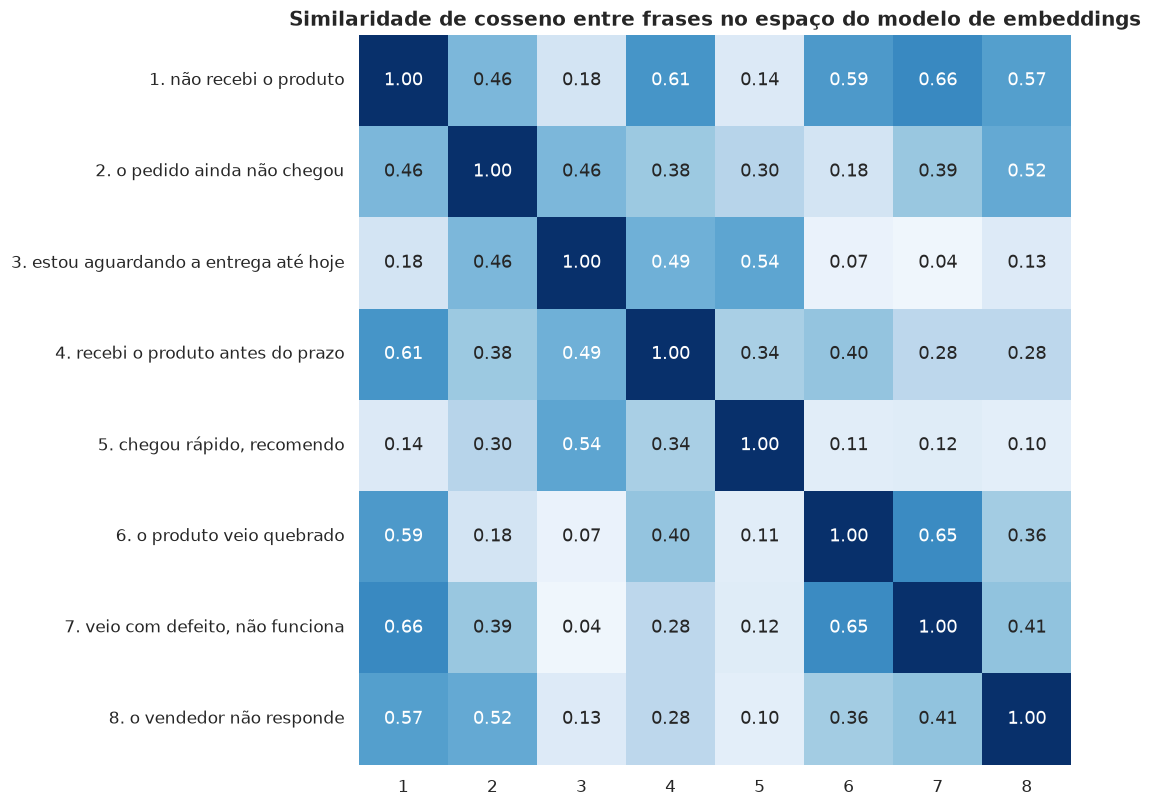

In [2]:
frases = [
    "não recebi o produto",
    "o pedido ainda não chegou",
    "estou aguardando a entrega até hoje",
    "recebi o produto antes do prazo",
    "chegou rápido, recomendo",
    "o produto veio quebrado",
    "veio com defeito, não funciona",
    "o vendedor não responde",
]
E = embed(frases)
sim = pd.DataFrame(E @ E.T, index=frases, columns=frases).round(2)
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
            xticklabels=[f"{i + 1}" for i in range(len(frases))])
ax.set_yticklabels([f"{i + 1}. {f}" for i, f in enumerate(frases)], rotation=0)
ax.set(title="Similaridade de cosseno entre frases no espaço do modelo de embeddings")
save(fig, "03_similaridade_frases");

O modelo aproxima frases do mesmo assunto ("veio quebrado" e "veio com defeito": 0,65), mas mede mais o assunto e as palavras em comum do que o sentido. **"Não recebi o produto" fica mais perto de "recebi o produto antes do prazo" (0,61) do que de "o pedido ainda não chegou" (0,46)**, e "estou aguardando a entrega até hoje" fica a 0,54 de "chegou rápido, recomendo". A negação e a polaridade pesam pouco no vetor.

Essa é uma limitação conhecida dos bi-encoders e muda o desenho do pipeline: a busca vetorial sozinha mistura elogio e reclamação do mesmo assunto. Três peças compensam: os filtros por nota e entrega (D09), o BM25, que mantém o "não" como termo (D22), e o re-ranking com cross-encoder, que lê pergunta e avaliação juntas (D08).

## 2. Tamanho e latência

Tempo médio de 20 buscas por um top-50, já com os índices carregados.

In [3]:
def medir(fn, n=20):
    fn()
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return 1000 * (time.perf_counter() - t0) / n

pergunta = "o produto chegou quebrado"
qv = embed([pergunta])
mascara = docs.groupby("doc_id")["review_score"].min().reindex(vector.doc_ids).le(2).to_numpy()
lat = pd.Series({
    "BM25 (pergunta já tokenizada pelo índice)": medir(lambda: lexical.search(pergunta, k=50)),
    "TF-IDF": medir(lambda: tfidf.search(pergunta, k=50)),
    "embedding da pergunta": medir(lambda: embed([pergunta])),
    "FAISS IndexFlatIP, base inteira": medir(lambda: vector.search(qv[0], k=50)),
    "FAISS com filtro (só notas 1 e 2)": medir(lambda: vector.search(qv[0], k=50, allowed=mascara)),
}).round(2)
print(f"entradas com alguma avaliação de nota 1 ou 2: {mascara.sum():,}".replace(",", "."))
print(f"memória dos vetores em float32: {vector.vectors.nbytes / 1e6:.1f} MB | em disco (float16): {Path('data/index/embeddings.npz').stat().st_size / 1e6:.1f} MB")
lat.to_frame("ms por busca")

entradas com alguma avaliação de nota 1 ou 2: 10.301
memória dos vetores em float32: 53.6 MB | em disco (float16): 28.5 MB


,ms por busca
BM25 (pergunta já tokenizada pelo índice),27.95
TF-IDF,5.86
embedding da pergunta,28.62
"FAISS IndexFlatIP, base inteira",9.76
FAISS com filtro (só notas 1 e 2),6.06


**D06: FAISS `IndexFlatIP`, busca exata.** A busca vetorial na base inteira leva cerca de 12 ms e, com filtro, 5 ms; o embedding da pergunta custa outros 21 ms. Um índice aproximado (HNSW ou IVF, vistos na aula de bancos vetoriais) trocaria precisão por velocidade, e nesta escala não há velocidade a ganhar. Os vetores ocupam 54 MB em memória e 28 MB em disco. O índice é montado na carga a partir dos vetores, e o filtro chega como um seletor de ids do FAISS.

## 3. Os três métodos na mesma pergunta

Os cinco primeiros de cada método para três perguntas. A coluna `avaliações` mostra quantas avaliações compartilham aquele texto (D04).

In [4]:
def mostrar(q, k=5):
    linhas = []
    for nome, idx in [("BM25", lexical), ("TF-IDF", tfidf), ("vetorial", vector)]:
        for pos, (d, s) in enumerate(idx.search(q, k=k), 1):
            linhas.append({"método": nome, "pos": pos, "score": round(s, 3),
                           "nota": int(rep.loc[d, "review_score"]), "avaliações": int(rep.loc[d, "doc_size"]),
                           "texto": rep.loc[d, "text_clean"][:85]})
    return pd.DataFrame(linhas).set_index(["método", "pos"])

mostrar("o pedido não chegou até hoje")

score  nota  avaliações                                                                                  texto
método   pos                                                                                                                 
BM25     1    10.332     1           1                                          Não entregue. Não entregou o pedido até hoje.
         2     9.938     1           1  Ate hoje o pedido não chegou entramos em contato com vocês e não tem nenhuma posição,
         3     9.574     1           2                                                         o PRODUTO NÃO CHEGOU ATÉ HOJE.
         4     9.341     1           1           Ate hoje não recebi e percebi que deram como se eu tivesse pedido devolução,
         5     8.965     1           1                                        Comprei a mais de um mês e não chegou até hoje!
TF-IDF   1     0.835     1           2                                                         o PRODUTO NÃO CHEGOU ATÉ HOJE.
         2     0.829     1           1                                          Não entregue. Não entregou o pedido até hoje.
         3     0.712     1           1                                                    O produto não foi entregue até hoje
         4     0.712     2           1                                                  Meu produto não foi entregue até hoje
         5     0.710     1           1                                                                  Ate hoje não recebi .
vetorial 1     0.906     1           1                                          Não entregue. Não entregou o pedido até hoje.
         2     0.862     1           1                                                             Pedido ainda não entregue.
         3     0.824     1           1                                                          O meu pedido ainda não chegou
         4     0.824     2           1                                  Meu pedido ainda não foi. Meu pedido não foi entregue
         5     0.788     3           1                        Chegou, porém não no prazo estipulado na hora de gerar o pedido

In [5]:
mostrar("produto diferente do anunciado")

score  nota  avaliações                                                                                  texto
método   pos                                                                                                                 
BM25     1    11.447     3           2                                                         PRODUTO DIFERENTE DO ANUNCIADO
         2    11.357     2           1                                                         estampa diferente do anunciado
         3    10.686     1           1              Produto Diferente. O produto que recebi é diferente do produto anunciado.
         4    10.670     1           1                                               Recebi um produto diferente do anunciado
         5    10.670     1           1                                                 Anunciou um produto entregou diferente
TF-IDF   1     1.000     3           2                                                         PRODUTO DIFERENTE DO ANUNCIADO
         2     0.958     1           1                                                 Anunciou um produto entregou diferente
         3     0.934     1           1                                               O produto chegou diferente do anunciado.
         4     0.934     1           1              Produto Diferente. O produto que recebi é diferente do produto anunciado.
         5     0.932     1           1                                               Recebi um produto diferente do anunciado
vetorial 1     0.877     2           1                                                    O produto veio diferente do anuncio
         2     0.838     1           1                                               Recebi um produto diferente do anunciado
         3     0.829     5           1                                                         produto de acordo com anuncio.
         4     0.829     1           1  Incorreto. O produto oferecido no anúncio é um, mas o que foi entregue se difere de f
         5     0.826     1           1                                               O produto chegou diferente do anunciado.

In [6]:
mostrar("vendedor não responde as mensagens")

score  nota  avaliações                                                                                  texto
método   pos                                                                                                                 
BM25     1    13.703     1           1  Meu pedido já passou do prazo e o cara da empresa nem responder minhas mensagens não 
         2    12.058     1           1          Não recebi meu produto,e ja mandei mensagem pra loja mas ninguém me responde.
         3    11.912     1           1  O produto simplesmente não chegou, enviei mensagem para saber o que houve e até agora
         4    11.381     1           1  Não consigo contato com o 0800, enviei mensagem comunicando mas não me responderam. P
         5    11.381     4           1  Não recebi o produto, enviei mensagem não me responderam, liguei estou esperando até 
TF-IDF   1     0.636     1           1  Meu pedido já passou do prazo e o cara da empresa nem responder minhas mensagens não 
         2     0.601     1           1          Não recebi meu produto,e ja mandei mensagem pra loja mas ninguém me responde.
         3     0.588     1           1  O produto simplesmente não chegou, enviei mensagem para saber o que houve e até agora
         4     0.579     4           1  Não recebi o produto, enviei mensagem não me responderam, liguei estou esperando até 
         5     0.569     1           1                                       Não chegou. Essa mensagem chegou e o produto não
vetorial 1     0.732     1           1  Empresa não entrega os produtos na data e não entra em contato com o cliente. Também 
         2     0.714     1           1  Vende produto indisponível, não resolve o problema do cliente, não responde os e-mail
         3     0.707     1           1          Não recebi meu produto,e ja mandei mensagem pra loja mas ninguém me responde.
         4     0.701     1           1  Produto não foi entregue. Sem resposta das lojas lannister e sem respostas da empresa
         5     0.679     1           1  Não recebi nem ao menos, nenhuma notificação do destino do produto. É uma falta de re

- **Pedido que não chegou:** os três métodos acertam. O BM25 e o TF-IDF ficam presos às palavras "até hoje"; o vetorial traz paráfrases sem elas ("pedido ainda não entregue"), mas no 5º lugar aparece "chegou, porém não no prazo", que é atraso, não falta de entrega.
- **Produto diferente do anunciado:** o vetorial coloca "produto de acordo com anúncio", uma avaliação de nota 5, em 3º lugar. É a limitação da seção 1 aparecendo numa busca real: o assunto bate e a polaridade é a oposta.
- **Vendedor que não responde:** BM25 e TF-IDF trazem avaliações com "mensagem" e "responde", quase todas sobre pedido não entregue; o vetorial traz a ideia de falta de resposta mesmo com outras palavras ("não entra em contato", "não responde os e-mails").

Nenhum método domina: o lexical é preciso quando o cliente usa a palavra da pergunta, o vetorial cobre as paráfrases e erra a polaridade.

## 4. Uma medida objetiva, sem juiz

Para duas perguntas existe gabarito nos metadados: o grupo "não recebeu" (pedido não entregue, cancelado ou cliente que respondeu antes de receber, D19) e o grupo de pedidos entregues com atraso. A precisão@50 é a fração dos 50 primeiros resultados cujas avaliações pertencem ao grupo (média por entrada, quando o texto representa várias avaliações). É uma prévia da avaliação completa do notebook 05, sem filtro e sem re-ranking.

In [7]:
alvo_nr = docs["delivery_status"].isin(["nao entregue", "cancelada"]) | docs["answered_before_delivery"]
frac_nr = alvo_nr.groupby(docs["doc_id"]).mean()
entregues = docs[docs["delivery_status"].isin(["no prazo", "atrasada"])]
frac_late = (entregues["delivery_status"] == "atrasada").groupby(entregues["doc_id"]).mean()
usa_receb = docs.drop_duplicates("doc_id").set_index("doc_id")["text_norm"].str.contains(r"\breceb")

def precisao_objetiva(q, alvo, k=50):
    linhas = {}
    for nome, idx in [("BM25", lexical), ("TF-IDF", tfidf), ("vetorial", vector)]:
        ids = [d for d, _ in idx.search(q, k=k)]
        linhas[nome] = {
            f"precisão@{k} (metadado)": 100 * alvo.reindex(ids).fillna(0).mean(),
            "% sem a palavra 'receber'": 100 * (~usa_receb.loc[ids]).mean(),
        }
    return pd.DataFrame(linhas).T.round(1)

print("base: % das entradas no grupo 'não recebeu':", round(100 * frac_nr.mean(), 1))
precisao_objetiva("não recebi o produto", frac_nr)

base: % das entradas no grupo 'não recebeu': 12.9


,precisão@50 (metadado),% sem a palavra 'receber'
BM25,62.4,0.0
TF-IDF,58.5,0.0
vetorial,69.1,14.0


In [8]:
print("base: % das entradas de pedidos entregues que chegaram atrasados:", round(100 * frac_late.mean(), 1))
precisao_objetiva("o pedido chegou atrasado", frac_late).iloc[:, :1]

base: % das entradas de pedidos entregues que chegaram atrasados: 10.2


,precisão@50 (metadado)
BM25,59.0
TF-IDF,68.8
vetorial,56.0


Os três métodos ficam muito acima da taxa base (13% e 10%), e nenhum vence nas duas perguntas:

- **"Não recebi o produto":** o vetorial chega a 69%, contra 62% do BM25 e 59% do TF-IDF, e 14% do que ele traz não usa nenhuma forma de "receber". É o ganho de cobertura que a HT3 do notebook 02 previa.
- **"O pedido chegou atrasado":** o TF-IDF fica à frente (69%), com o BM25 em 59% e o vetorial em 56%. "Atrasado" é uma palavra que o cliente usa literalmente, e o vetorial dilui o sinal com textos que falam de prazo em geral, inclusive elogios.

**D07 confirmada como desenho:** a combinação dos dois ramos é o que a ablação vai medir. O TF-IDF fica como referência; o ramo lexical do pipeline é o BM25, que é o previsto na aula e satura a frequência do termo. Se a ablação mostrar o TF-IDF à frente no conjunto completo, isso vira limitação declarada.

## 5. Como o espaço se organiza

Projeção t-SNE (aula de NLP 4) de uma amostra de 4.000 textos, colorida pela nota e pela situação da entrega da avaliação representante de cada texto.

In [9]:
from sklearn.manifold import TSNE

rng = np.random.default_rng(42)
amostra = rng.choice(len(vector), size=4000, replace=False)
t0 = time.perf_counter()
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(vector.vectors[amostra])
print(f"t-SNE em {time.perf_counter() - t0:.0f} s")
proj = rep.iloc[amostra][["review_score", "delivery_status", "text_clean"]].assign(x=xy[:, 0], y=xy[:, 1])
proj["grupo"] = np.select([proj["review_score"] <= 2, proj["review_score"] >= 4], ["notas 1 e 2", "notas 4 e 5"], "nota 3")

t-SNE em 26 s


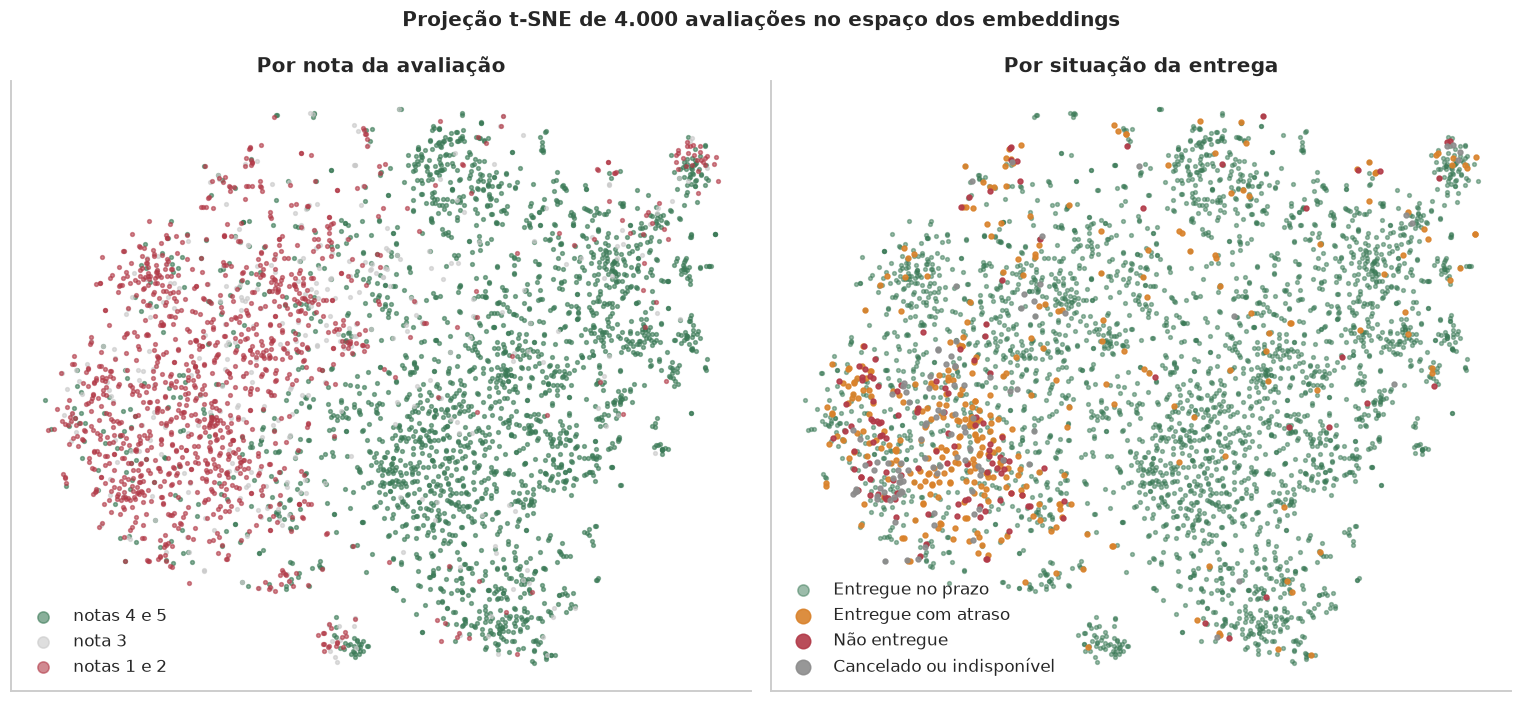

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for g, cor in [("notas 4 e 5", GREEN), ("nota 3", "#c9c9c9"), ("notas 1 e 2", RED)]:
    p = proj[proj["grupo"] == g]
    axes[0].scatter(p["x"], p["y"], s=6, alpha=0.6, color=cor, label=g)
axes[0].set(title="Por nota da avaliação")
axes[0].legend(markerscale=3, loc="lower left")
for s in ["no prazo", "atrasada", "nao entregue", "cancelada"]:
    p = proj[proj["delivery_status"] == s]
    axes[1].scatter(p["x"], p["y"], s=6 if s == "no prazo" else 10, alpha=0.5 if s == "no prazo" else 0.9,
                    color=DELIVERY_COLORS[s], label=DELIVERY_LABELS[s])
axes[1].set(title="Por situação da entrega")
axes[1].legend(markerscale=3, loc="lower left")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Projeção t-SNE de 4.000 avaliações no espaço dos embeddings", fontweight="bold", fontsize=13)
save(fig, "03_tsne");

In [11]:
# vizinhança: as 5 avaliações mais próximas de três pontos da projeção
for q in ["chegou antes do prazo", "não recebi meu pedido", "produto de péssima qualidade"]:
    print(q, "->", [rep.loc[d, "text_clean"][:45] for d, _ in vector.search(q, k=5)])

chegou antes do prazo -> ['Veio antes do prazo', 'chegou antes do prazo previsto', 'recomento. chegou antes do prazo.', 'Veio até antes do prazo', 'Chegou antes até do prazo']
não recebi meu pedido -> ['Não recebi o pedido', 'Não recebi meu pedido!', 'Não foi entregue o meu pedido', 'Nãorecebi meu pedido. Não recebi nenhum', 'Não recebi meu pedido completo.']
produto de péssima qualidade -> ['produto de má qualidade', 'Péssima qualidade do produto', 'Produto de péssima qualidade', 'o produto de péssima qualidade !', 'produto ruim. produto de má qualidade']


O espaço se divide de forma clara entre notas baixas (à esquerda) e notas altas (à direita), mesmo com a fraqueza de polaridade vista na seção 1: frases inteiras de reclamação e de elogio usam vocabulários diferentes, e o modelo capta isso. As entregas atrasadas, não entregues e canceladas se concentram dentro da região negativa. As ilhas pequenas são textos curtos e repetitivos ("chegou antes do prazo"), como mostram os vizinhos mais próximos.

**Para o gestor:** a busca semântica encontra o assunto e a região de sentimento certos, mas não garante a polaridade de cada frase. Por isso as respostas sobre reclamações usam o filtro de nota e passam pelo re-ranking antes de virar evidência.

## 6. O que fica decidido

| Decisão | Evidência |
|---|---|
| D05 `paraphrase-multilingual-MiniLM-L12-v2`, vetores normalizados | paráfrases próximas; documentos cabem no limite de 128 tokens (notebook 02) |
| D06 FAISS `IndexFlatIP` | 12 ms por busca exata em 34.889 vetores; nada a ganhar com índice aproximado |
| D07 busca híbrida | vetorial vence em "não recebi" (69% contra 62%), lexical vence em "atrasado" (59% e 69% contra 56%) |
| D08 re-ranking com cross-encoder | o bi-encoder aproxima "não recebi" de "recebi antes do prazo" (0,61) e traz um elogio para "produto diferente do anunciado" |

O próximo notebook usa os mesmos embeddings para construir o mapa de temas.